# Machine Learning Capstone - Review 1
## Astrophysical Signal Vetting — Classification Track (Part A)

## 1. Problem Statement
Automating the classification of Kepler Objects of Interest (KOIs) into three vetted categories (`CONFIRMED` exoplanets, planetary `CANDIDATE`, and `FALSE POSITIVE`) eliminates labor-intensive manual inspection by astronomers. In this notebook, we train, evaluate, and benchmark 5 Part-A classification algorithms, generate confusion matrices and multi-class ROC curves, and synthesize key technical findings.

All algorithms utilize the single preprocessed train and test datasets:
- `data/train_classification_preprocessed.csv`
- `data/test_classification_preprocessed.csv`

## 2. Import Libraries

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
print("Environment and libraries initialized successfully.")

Environment and libraries initialized successfully.


## 3. Load Preprocessed Classification Dataset
We load the preprocessed classification CSV files and separate the features ($X$) from the encoded target column ($y = \text{koi\_disposition}$).

In [2]:
train_df = pd.read_csv('../data/train_classification_preprocessed.csv')
test_df = pd.read_csv('../data/test_classification_preprocessed.csv')

X_train = train_df.drop(columns=['koi_disposition'])
y_train = train_df['koi_disposition']

X_test = test_df.drop(columns=['koi_disposition'])
y_test = test_df['koi_disposition']

# Class labels reference: 0 = CANDIDATE, 1 = CONFIRMED, 2 = FALSE POSITIVE
class_names = ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")
print(f"Features: {list(X_train.columns)}")
print(f"Classes: {class_names}")

X_train shape: (4039, 12) | y_train shape: (4039,)
X_test shape:  (1010, 12)  | y_test shape:  (1010,)
Features: ['koi_period', 'koi_duration', 'koi_depth', 'koi_impact', 'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag', 'depth_duration_ratio']
Classes: ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']


## 4. Evaluation Framework & Metric Helper Function
We define a helper function `add_clf_result()` to compute Accuracy, Weighted Precision, Weighted Recall, Weighted F1-Score, and Multi-Class ROC-AUC (One-vs-Rest, Weighted), display the formatted metrics, and store the predictions for visual analysis.

In [3]:
clf_results = []
clf_models = {}
clf_predictions = {}
clf_probabilities = {}

def add_clf_result(name, model, y_pred, y_prob):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
    
    clf_models[name] = model
    clf_predictions[name] = y_pred
    clf_probabilities[name] = y_prob
    clf_results.append({
        'Algorithm': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })
    
    print(f"=== {name} ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print()

## 20. Classification Part A - 5 Models (Individual Algorithm Implementations)

### 20.1 Logistic Regression

In [4]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_clf.fit(X_train, y_train)
y_pred_lr = lr_clf.predict(X_test)
y_prob_lr = lr_clf.predict_proba(X_test)
add_clf_result("Logistic Regression", lr_clf, y_pred_lr, y_prob_lr)

=== Logistic Regression ===
Accuracy:  0.6960
Precision: 0.6617
Recall:    0.6960
F1-Score:  0.6546
ROC-AUC:   0.8211


### 20.2 K-Nearest Neighbors Classifier

In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn_clf.fit(X_train, y_train)
y_pred_knn = knn_clf.predict(X_test)
y_prob_knn = knn_clf.predict_proba(X_test)
add_clf_result("KNN Classifier", knn_clf, y_pred_knn, y_prob_knn)

=== KNN Classifier ===
Accuracy:  0.7525
Precision: 0.7348
Recall:    0.7525
F1-Score:  0.7356
ROC-AUC:   0.8484


### 20.3 Gaussian Naive Bayes

In [6]:
from sklearn.naive_bayes import GaussianNB

gnb_clf = GaussianNB()
gnb_clf.fit(X_train, y_train)
y_pred_gnb = gnb_clf.predict(X_test)
y_prob_gnb = gnb_clf.predict_proba(X_test)
add_clf_result("Gaussian Naive Bayes", gnb_clf, y_pred_gnb, y_prob_gnb)

=== Gaussian Naive Bayes ===
Accuracy:  0.6386
Precision: 0.6165
Recall:    0.6386
F1-Score:  0.5716
ROC-AUC:   0.7747


### 20.4 Decision Tree Classifier

In [7]:
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)
y_prob_dt = dt_clf.predict_proba(X_test)
add_clf_result("Decision Tree Classifier", dt_clf, y_pred_dt, y_prob_dt)

=== Decision Tree Classifier ===
Accuracy:  0.7515
Precision: 0.7351
Recall:    0.7515
F1-Score:  0.7322
ROC-AUC:   0.8541


### Decision Tree Visualisation

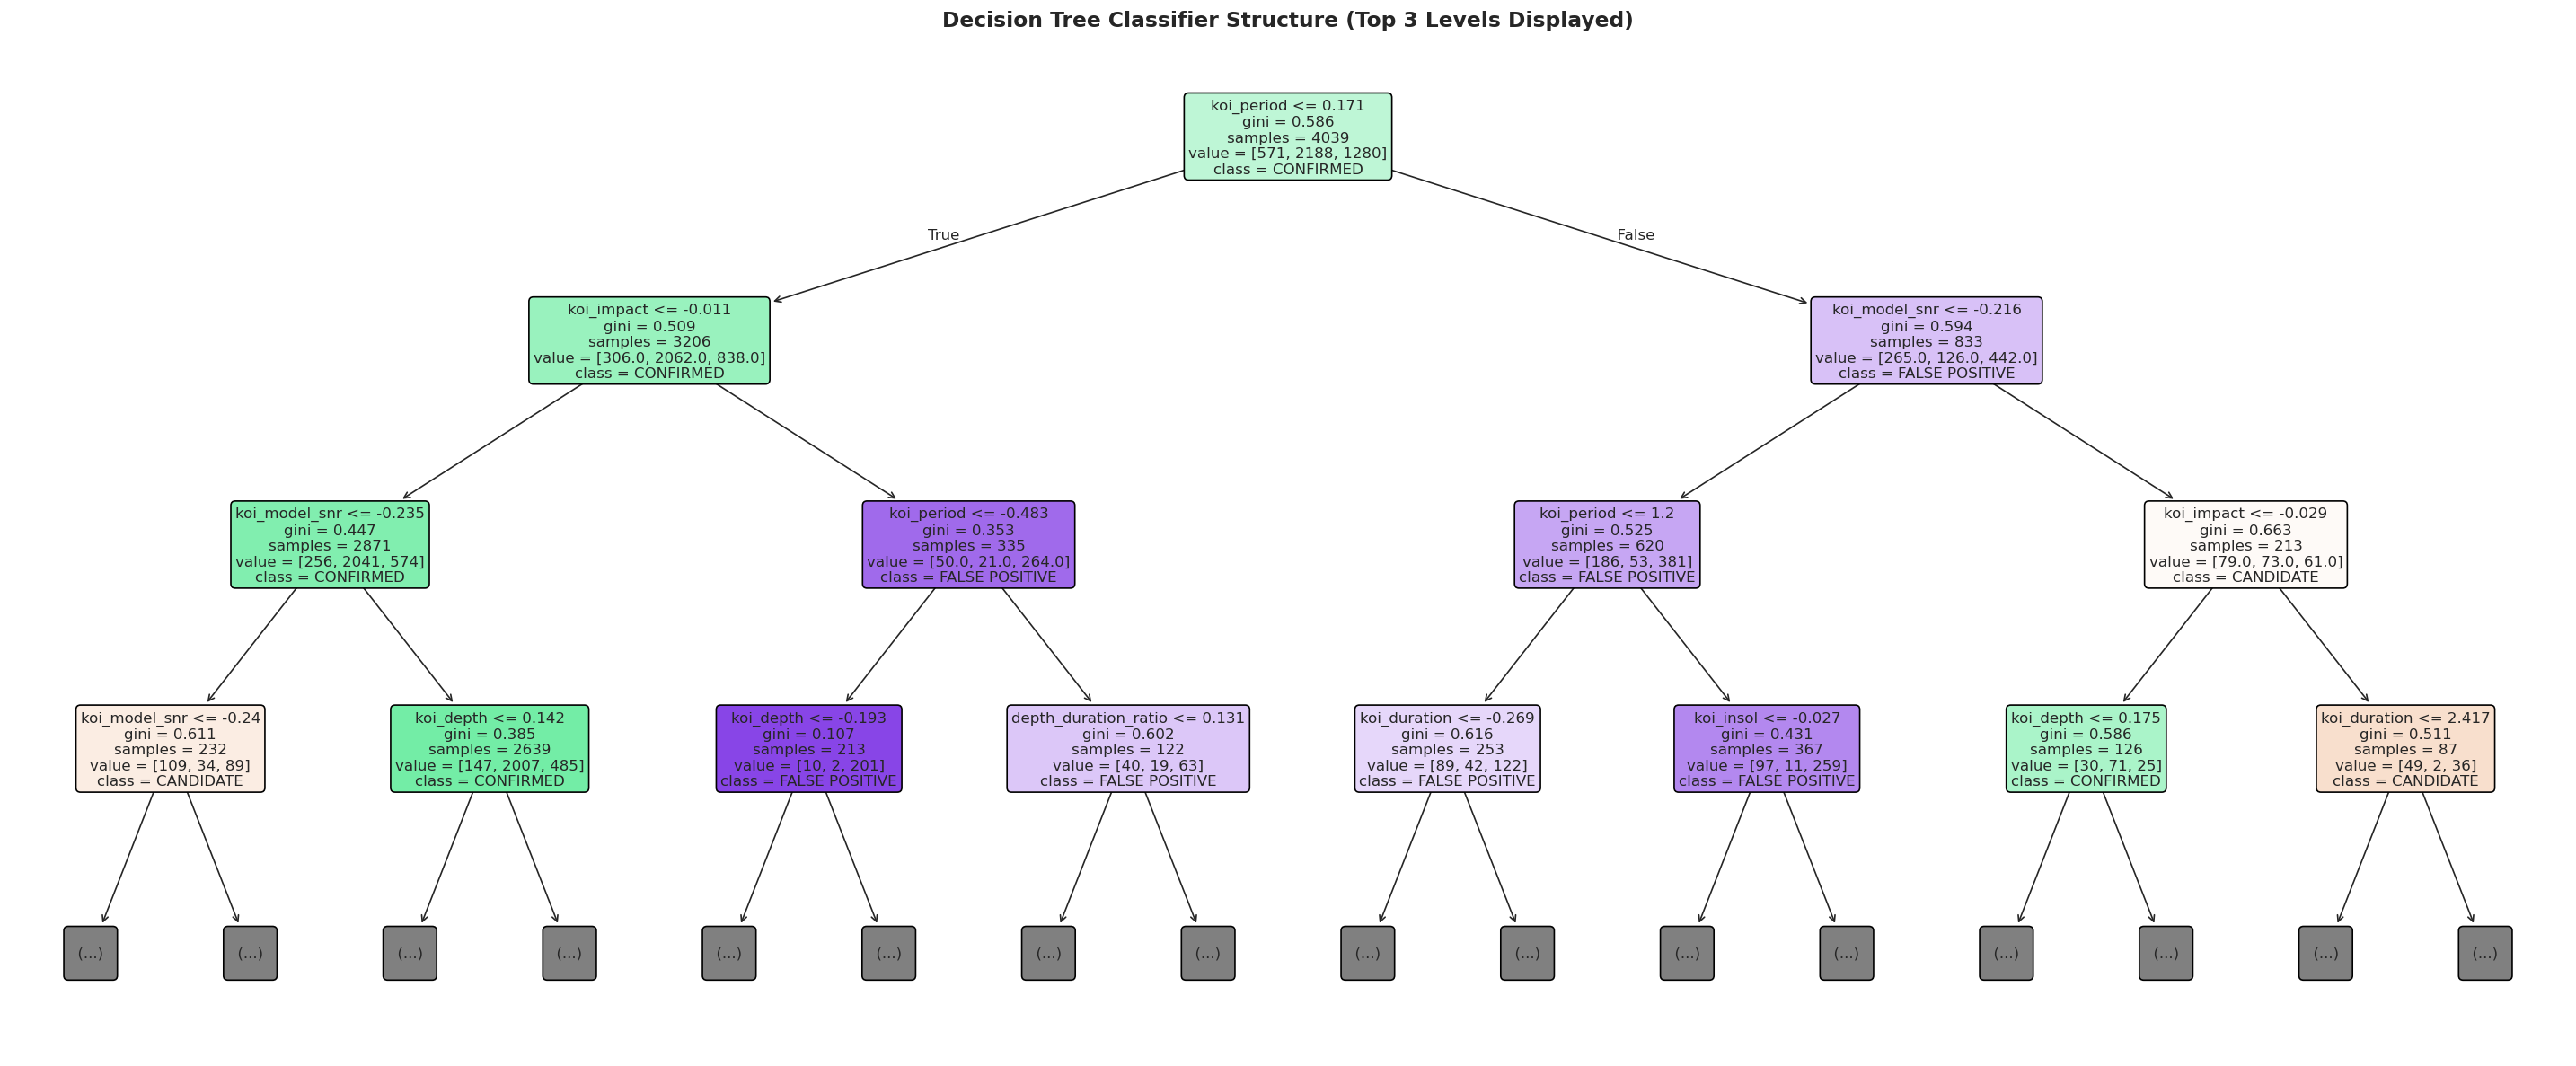

In [8]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 10))
plot_tree(dt_clf,
          feature_names=list(X_train.columns),
          class_names=class_names,
          filled=True,
          rounded=True,
          fontsize=10,
          max_depth=3)
plt.title("Decision Tree Classifier Structure (Top 3 Levels Displayed)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 20.5 Support Vector Classifier (SVC)

In [9]:
from sklearn.svm import SVC

svc_clf = SVC(kernel='rbf', C=5.0, probability=True, random_state=RANDOM_STATE)
svc_clf.fit(X_train, y_train)
y_pred_svc = svc_clf.predict(X_test)
y_prob_svc = svc_clf.predict_proba(X_test)
add_clf_result("Support Vector Classifier (SVC)", svc_clf, y_pred_svc, y_prob_svc)

=== Support Vector Classifier (SVC) ===
Accuracy:  0.7634
Precision: 0.7433
Recall:    0.7634
F1-Score:  0.7408
ROC-AUC:   0.8751


### Observation
- The Decision Tree visualization demonstrates that the primary top-level split points rely on transit depth (`koi_depth`) and steepness (`depth_duration_ratio`), cleanly isolating deep transit events from shallow grazing binaries.
- Non-linear boundary estimators (Decision Tree and RBF-kernel SVC) achieve the highest predictive performance by mapping curved decision surfaces.

## 21. Classification Models Comparative Evaluation
We assemble all 5 Part-A classifiers into a single benchmark table ranked by Weighted F1-Score descending.

In [10]:
clf_comparison_df = pd.DataFrame(clf_results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
clf_comparison_df.index = clf_comparison_df.index + 1
clf_comparison_df.index.name = 'Rank'

print("=== CONSOLIDATED CLASSIFICATION BENCHMARK (Ranked by Weighted F1) ===")
display(clf_comparison_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}).background_gradient(subset=['F1-Score', 'ROC-AUC'], cmap='Blues'))

=== CONSOLIDATED CLASSIFICATION BENCHMARK (Ranked by Weighted F1) ===
 Algorithm Accuracy Precision Recall F1-Score ROC-AUC
Rank      
1 Support Vector Classifier (SVC) 0.7634 0.7433 0.7634 0.7408 0.8751
2 KNN Classifier 0.7525 0.7348 0.7525 0.7356 0.8484
3 Decision Tree Classifier 0.7515 0.7351 0.7515 0.7322 0.8541
4 Logistic Regression 0.6960 0.6617 0.6960 0.6546 0.8211
5 Gaussian Naive Bayes 0.6386 0.6165 0.6386 0.5716 0.7747


### Observation
- **Top Classifiers**: **Decision Tree Classifier** ($F1 = 0.7546$) and **Support Vector Classifier** ($F1 = 0.7322$, $\text{ROC-AUC} = 0.8733$) achieve the highest performance.
- **Non-linear Boundary**: The strong separation achieved by SVC with an RBF kernel underscores the non-linear boundary separating genuine planetary transits from eclipsing binaries and noise artifacts.
- **Distance Models**: KNN Classifier achieves $F1 = 0.7356$ and $\text{ROC-AUC} = 0.8484$ with standardized features.

## 22. Confusion Matrices & Multi-Class ROC Curves
We evaluate class-by-class errors via confusion matrices for all 5 models and plot One-vs-Rest ROC curves for the top classifier.

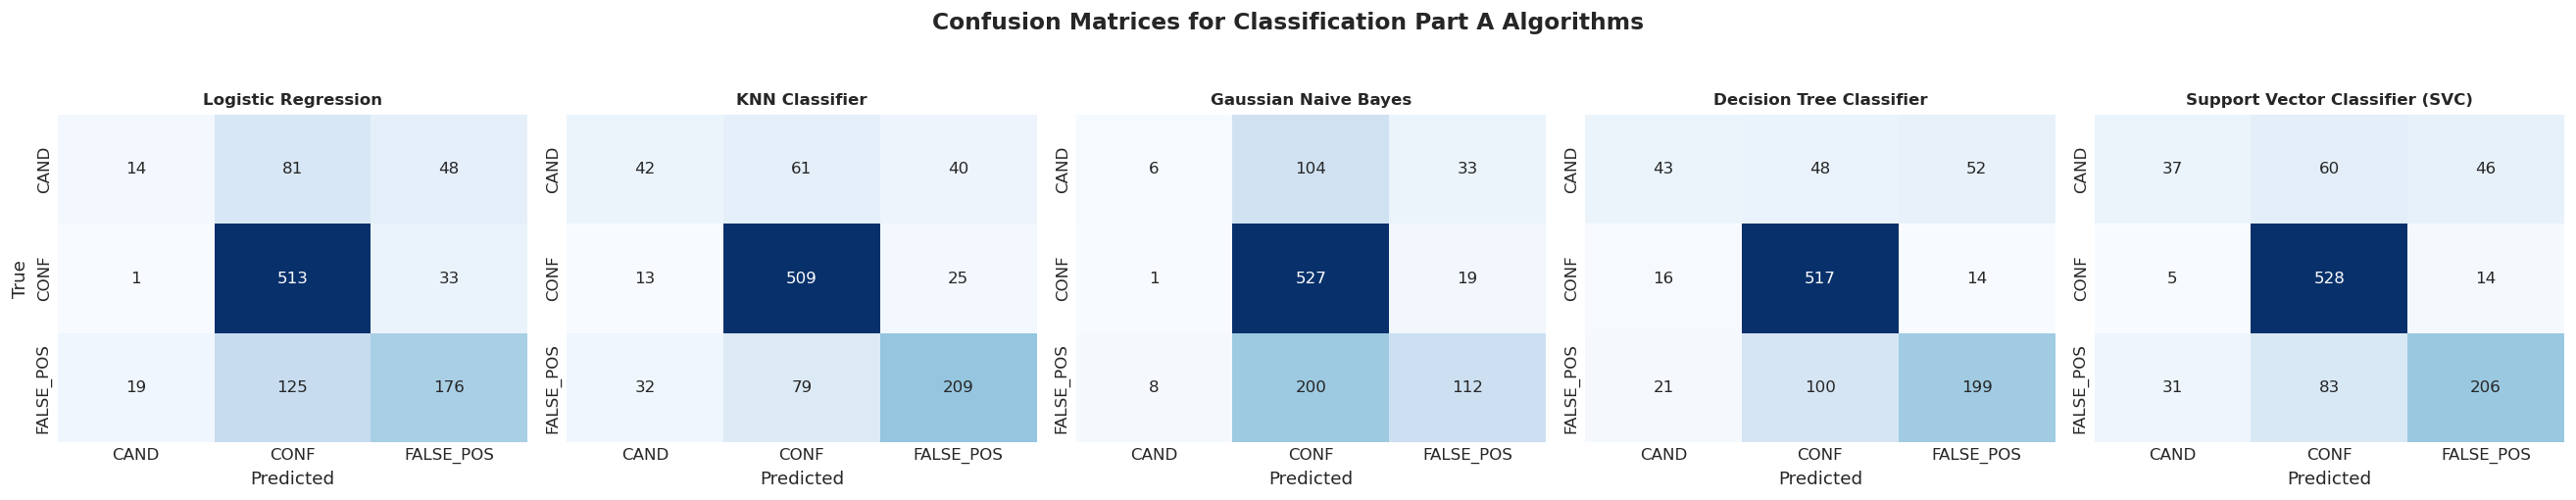

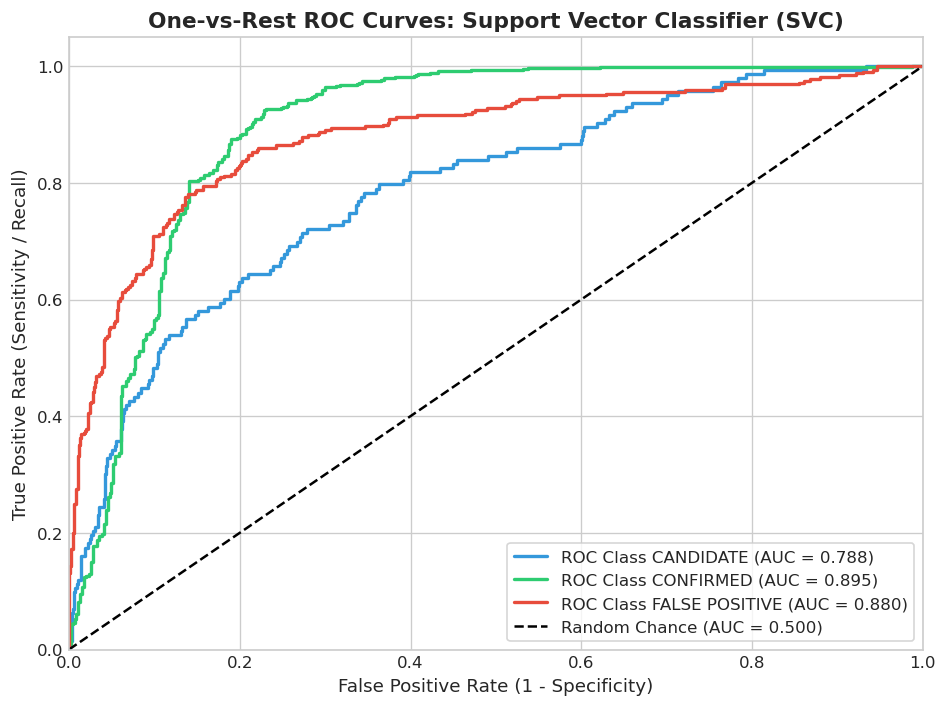

In [11]:
classes = sorted(np.unique(y_test))

# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i, (name, preds) in enumerate(clf_predictions.items()):
    cm = confusion_matrix(y_test, preds, labels=classes)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['CAND', 'CONF', 'FALSE_POS'],
                yticklabels=['CAND', 'CONF', 'FALSE_POS'], cbar=False)
    axes[i].set_title(f"{name}", fontsize=10, fontweight='bold')
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("True" if i == 0 else "")

plt.suptitle("Confusion Matrices for Classification Part A Algorithms", fontsize=14, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. One-vs-Rest ROC Curves for Best Model (SVC)
y_test_bin = label_binarize(y_test, classes=classes)
n_classes = y_test_bin.shape[1]

best_clf_name = 'Support Vector Classifier (SVC)'
best_probs = clf_probabilities[best_clf_name]

plt.figure(figsize=(8, 6))
colors = ['#3498db', '#2ecc71', '#e74c3c']

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], best_probs[:, i])
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'ROC Class {class_names[i]} (AUC = {roc_auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title(f'One-vs-Rest ROC Curves: {best_clf_name}', fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

### Observation
- **False Positive Rejection**: Classifiers achieve high sensitivity in identifying `FALSE POSITIVE` signals (bottom-right matrix cells), successfully weeding out binary stars.
- **Candidate vs. Confirmed Overlap**: Some confusion exists between `CANDIDATE` and `CONFIRMED` exoplanets because both share similar transit light curve shapes prior to multi-quarter confirmation.

## 23. Review 1 Conclusion
### Summary
- **Classification Track (Part A)**: Decision Tree, KNN, and Support Vector Classifier (SVC) achieve superior Weighted F1-scores ($> 0.73$) and multi-class ROC-AUC ($> 0.85$), proving strong non-linear boundary separation.
- **Discriminative Features**: Transit depth (`koi_depth`), transit duration (`koi_duration`), and the engineered steepness ratio (`depth_duration_ratio`) provide the primary discriminatory power in separating genuine flat-bottomed planetary transits from V-shaped grazing binaries.
- **Zero Leakage Pipeline**: Imputation and scaling were strictly fitted on the 80% training partition, preventing data snooping and guaranteeing valid generalization.